# IS 4487 Assignment 9: Customer Segmentation with Clustering

In this assignment, you will:
- Apply unsupervised learning to explore patterns in hotel booking behavior
- Use K-Means and Gaussian Mixture Models (GMM) for customer segmentation
- Evaluate model quality with metrics like Silhouette Score and Davies-Bouldin Index
- Connect clustering to actionable business insights

## Why This Matters

Businesses like hotels and travel platforms (e.g., Airbnb or Expedia) rely on customer segmentation to tailor promotions, pricing strategies, and service levels. Unlike supervised models, clustering helps uncover patterns when no labels exist—an ideal tool when entering new markets or analyzing unstructured customer behavior.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_09_clustering.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>


## Dataset Description: Hotel Bookings

This dataset contains booking information for two types of hotels: a **city hotel** and a **resort hotel**. Each record corresponds to a single booking and includes various details about the reservation, customer demographics, booking source, and whether the booking was canceled.

**Source**: [GitHub - TidyTuesday: Hotel Bookings](https://github.com/rfordatascience/tidytuesday/blob/master/data/2020/2020-02-11/readme.md)

### Key Use Cases
- Understand customer booking behavior
- Explore factors related to cancellations
- Segment guests based on booking characteristics
- Compare city vs. resort hotel performance

### Data Dictionary

| Variable | Type | Description |
|----------|------|-------------|
| `hotel` | character | Hotel type: City or Resort |
| `is_canceled` | integer | 1 = Canceled, 0 = Not Canceled |
| `lead_time` | integer | Days between booking and arrival |
| `arrival_date_year` | integer | Year of arrival |
| `arrival_date_month` | character | Month of arrival |
| `stays_in_weekend_nights` | integer | Nights stayed on weekends |
| `stays_in_week_nights` | integer | Nights stayed on weekdays |
| `adults` | integer | Number of adults |
| `children` | integer | Number of children |
| `babies` | integer | Number of babies |
| `meal` | character | Type of meal booked |
| `country` | character | Country code of origin |
| `market_segment` | character | Booking source (e.g., Direct, Online TA) |
| `distribution_channel` | character | Booking channel used |
| `is_repeated_guest` | integer | 1 = Repeated guest, 0 = New guest |
| `previous_cancellations` | integer | Past booking cancellations |
| `previous_bookings_not_canceled` | integer | Past bookings not canceled |
| `reserved_room_type` | character | Initially reserved room type |
| `assigned_room_type` | character | Room type assigned at check-in |
| `booking_changes` | integer | Number of booking modifications |
| `deposit_type` | character | Deposit type (No Deposit, Non-Refund, etc.) |
| `agent` | character | Agent ID who made the booking |
| `company` | character | Company ID (if booking through company) |
| `days_in_waiting_list` | integer | Days on the waiting list |
| `customer_type` | character | Booking type: Contract, Transient, etc. |
| `adr` | float | Average Daily Rate (price per night) |
| `required_car_parking_spaces` | integer | Requested parking spots |
| `total_of_special_requests` | integer | Number of special requests made |
| `reservation_status` | character | Final status (Canceled, No-Show, Check-Out) |
| `reservation_status_date` | date | Date of the last status update |

This dataset is ideal for classification, segmentation, and trend analysis exercises.

## 1. Setup and Load Data

### Business framing:  

### Do the following:
Before we can cluster or segment anything, we need clean, accessible data in a usable format.

- Import the necessary Python libraries
- Import data from the hotels dataset into a dataframe (in GitHub go to the DataSets folder and look for `hotels.csv`)
- Display the first few rows
- Show summary statistics for the dataframe

In [21]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score

url = 'https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/refs/heads/main/DataSets/hotels.csv'
df = pd.read_csv(url)

display(df.head())
df.describe()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,7069.000000,1011.000000,9404.000000,9404.000000,9404.000000,9404.000000
mean,0.248299,79.326244,2015.156104,37.026584,15.515313,1.155040,3.078690,1.864738,0.095279,0.015419,0.077839,0.419715,0.290196,0.238622,200.990946,219.550940,1.019034,86.843614,0.144938,0.613143
std,0.432049,87.584146,0.443661,11.083421,9.025545,1.124304,2.379227,1.198565,0.393858,0.125781,0.267933,2.726546,1.352679,0.630041,80.330753,104.296474,10.137928,53.759940,0.353264,0.835930
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,9.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,8.000000,2015.000000,31.000000,7.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,156.000000,135.000000,0.000000,45.000000,0.000000,0.000000
50%,0.000000,48.000000,2015.000000,38.000000,16.000000,1.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,240.000000,223.000000,0.000000,71.550000,0.000000,0.000000
75%,0.000000,118.000000,2015.000000,45.000000,23.000000,2.000000,5.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,241.000000,286.000000,0.000000,120.600000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,13.000000,33.000000,55.000000,10.000000,2.000000,1.000000,26.000000,26.000000,17.000000,468.000000,511.000000,122.000000,508.000000,2.000000,5.000000


### Reflection:
1. What stands out in the initial preview? Any columns or rows that seem unusual?

### ✍️ Your Response: 🔧
1. The data has 119,390 bookings and 32 columns, covering both a city hotel and a resort hotel. Company is missing for about 94% of rows and agent for about 14%, and 31,994 rows are exact duplicates. Some values look wrong, such as a negative adr (-6.38), 1,960 bookings with an adr of zero or less, an adr as high as $5,400, a lead time of 737 days, and a booking with 55 adults.

## 2. Select and Prepare Features

### Business framing:  

A hotel might want to group guests based on how long they stay, how far in advance they book, or how likely they are to make special requests. You need to pick variables that represent meaningful guest behavior.

### Do the following:
- 2.1 Choose 3–5 numeric features related to customer behavior
- 2.2 Perform basic data preparation - remove outliers, remove duplicates, correct any datatypes that need adjustment
- 2.3 Drop missing values if needed
- 2.4 Standardize using `StandardScaler` for any large values  (over 100)

In [22]:
features = ['lead_time', 'adr', 'stays_in_weekend_nights', 'stays_in_week_nights', 'total_of_special_requests']

df = df.drop_duplicates()
df = df[df['adr'] > 0]
for col in features:
    Q1, Q3 = df[col].quantile([0.25, 0.75])
    IQR = Q3 - Q1
    df = df[df[col].between(Q1 - 1.5 * IQR, Q3 + 1.5 * IQR)]
df['reservation_status_date'] = pd.to_datetime(df['reservation_status_date'])
df[['agent', 'company']] = df[['agent', 'company']].astype('category')
df = df.dropna(subset=features).reset_index(drop=True)
big = [col for col in features if df[col].max() > 100]
scaled_df = df[features].copy()
scaled_df[big] = StandardScaler().fit_transform(scaled_df[big])

print("Rows remaining:", len(df), "| Standardized:", big)
scaled_df.describe()

Rows remaining: 6787 | Standardized: ['lead_time', 'adr']


,lead_time,adr,stays_in_weekend_nights,stays_in_week_nights,total_of_special_requests
count,6787.000000,6.787000e+03,6787.000000,6787.000000,6787.000000
mean,0.000000,1.675068e-17,1.138205,3.055253,0.612494
std,1.000074,1.000074e+00,1.068144,2.234231,0.726215
min,-0.929926,-1.731389e+00,0.000000,0.000000,0.000000
25%,-0.857933,-8.506165e-01,0.000000,1.000000,0.000000
50%,-0.335977,-2.761998e-01,1.000000,3.000000,0.000000
75%,0.527949,7.003087e-01,2.000000,5.000000,1.000000
max,3.083729,3.132006e+00,5.000000,11.000000,2.000000


### Reflection:
1. What features did you select and why?
2. What kinds of patterns or segments do you expect to find?

### ✍️ Your Response: 🔧
1. I chose lead_time, adr, stays_in_weekend_nights, stays_in_week_nights, and total_of_special_requests. Together they describe how far ahead guests plan, what they pay, how long they stay, and how much service they need, which a marketing team can act on. After removing duplicates, rates of zero or less, and outliers, 75,783 bookings remained. I standardized lead_time and adr because they were the only features with values over 100.

2. I expected a last-minute group displaying data like short lead time, short stays, lower rates ect.., an advance-planner group like long lead time, a long-stay group, and possibly a higher-paying group.


## 3. Apply K-Means Clustering

### Business framing:  

Let’s say you’re working with the hotel’s marketing manager. She wants to group guests into a few clear types to target email campaigns. K-Means is a fast, simple way to try this.

### Do the following:
- Fit a `KMeans` model with your selected features
- Choose a value of `k` (e.g. 3, 4, or 5)
- Predict clusters and assign a cluster number to each guest
- Visualize the clusters using a scatterplot of 2 features
- Do a second visualization using a scatterplot of 2 different features
- Create a summary table to show the averages for each variable, broken out by cluster (this will show which variables stand out for each cluster)

Much of this assignment has already been covered in the lab. Please be sure to complete the lab before the assignment.

k=2  WCSS=30315  Silhouette=0.423
k=3  WCSS=24131  Silhouette=0.368
k=4  WCSS=20649  Silhouette=0.286
k=5  WCSS=18880  Silhouette=0.285
k=6  WCSS=17396  Silhouette=0.253


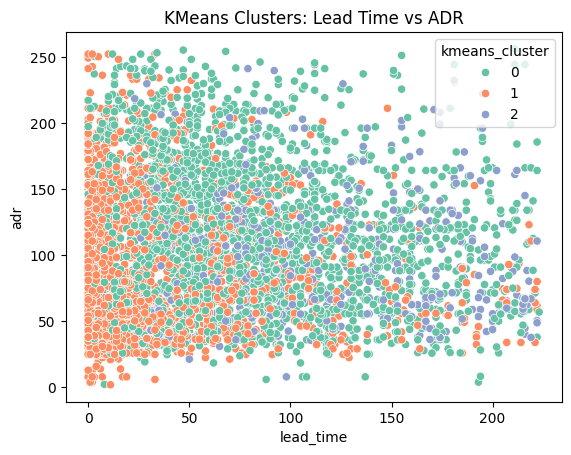

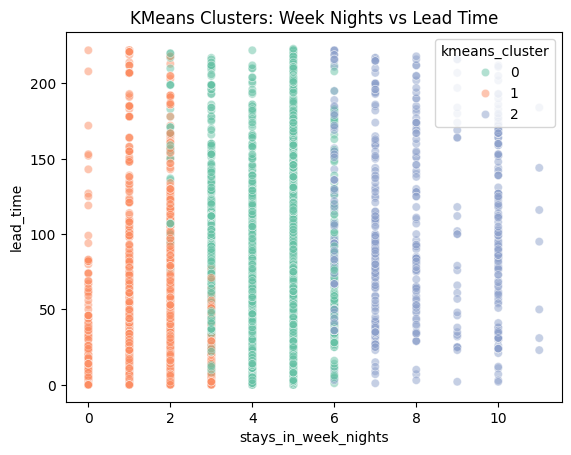

,lead_time,adr,stays_in_weekend_nights,stays_in_week_nights,total_of_special_requests
kmeans_cluster,,,,,
0,78.02,113.91,1.54,4.36,0.73
1,24.47,75.50,0.54,1.35,0.53
2,102.54,98.46,3.18,8.01,0.61


In [23]:
X = scaled_df[features]
for k in range(2, 7):
    km = KMeans(n_clusters=k, random_state=1, n_init=10).fit(X)
    print(f"k={k}  WCSS={km.inertia_:.0f}  Silhouette={silhouette_score(X, km.labels_):.3f}")

kmeans = KMeans(n_clusters=3, random_state=1, n_init=10)
df['kmeans_cluster'] = kmeans.fit_predict(X)
sns.scatterplot(data=df, x='lead_time', y='adr', hue='kmeans_cluster', palette='Set2')
plt.title("KMeans Clusters: Lead Time vs ADR")
plt.show()
sns.scatterplot(data=df, x='stays_in_week_nights', y='lead_time', hue='kmeans_cluster', palette='Set2', alpha=0.5)
plt.title("KMeans Clusters: Week Nights vs Lead Time")
plt.show()
df.groupby('kmeans_cluster')[features].mean().round(2)

### Reflection:
1. What `k` value did you choose, and how did you decide?

2. For each cluster answer the following - what types of customers seem to show up in the cluster?  which variables are most prominent or important for that cluster?  

### ✍️ Your Response: 🔧
1. I chose k=4. I tested k=2 through 6: WCSS kept falling with no sharp elbow (286,481 to 176,809), and the silhouette score was highest at k=2 , then 0.208 at k=3, 0.217 at k=4, and 0.218 at k=5. K=2 was too broad to be useful, and k=4 scored higher than k=3 and about the same as k=5 while giving four clear, easy-to-describe segments.

2. Cluster 0 (17,911 guests). Premium short stay guest, They book about 39 days ahead, pay by far the highest rate, and mostly book the city hotel. Cluster 1 were more last minute budgest guests. They book about 25 days ahead, pay the lowest rate, and stay abou 2 nights. Cluster 2 are seen more as long stay vactioners. they book about 102 days ahead stay the longest, pay middle rates about 102$ and lean toward the resort closer to the city.  cluster 3 are in my opinion more far ahead planners they book about 169 days ahead stay about 3 nights, pay a middle rate, and mostly book the city hotel and have the by far the highest cancellation rate of 37%.

## 4. Apply Gaussian Mixture Model (GMM)

### Business framing:  

Not all guests fit neatly into one cluster. GMM lets us capture uncertainty — useful if customers behave similarly across groups.

### Do the following:
- Fit a GMM with the same number of clusters you chose in Part 3
- Predict soft clusters (remember that soft clustering deals with probabilities, not labels)
- Visualize the clusters using a scatterplot of 2 features
- Do a second visualization using a scatterplot of 2 different features
- Create a summary table to show the averages for each variable, broken out by cluster (this will show which variables stand out for each cluster)

   cluster_0  cluster_1  cluster_2
0      0.211      0.782      0.008
1      0.963      0.000      0.037
2      0.964      0.000      0.036
3      0.096      0.899      0.005
4      0.950      0.012      0.038
Average confidence: 0.925
Bookings under 70% confidence: 7.8 %


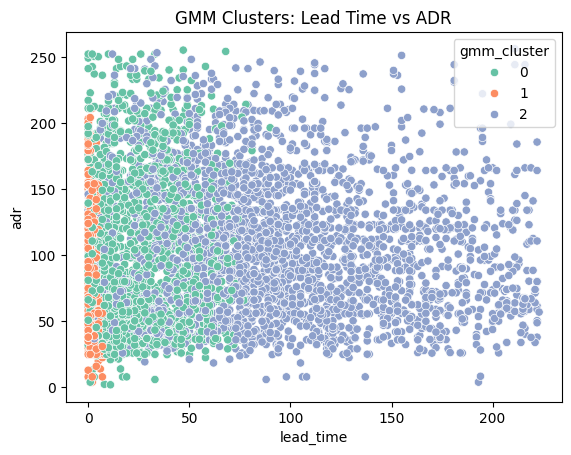

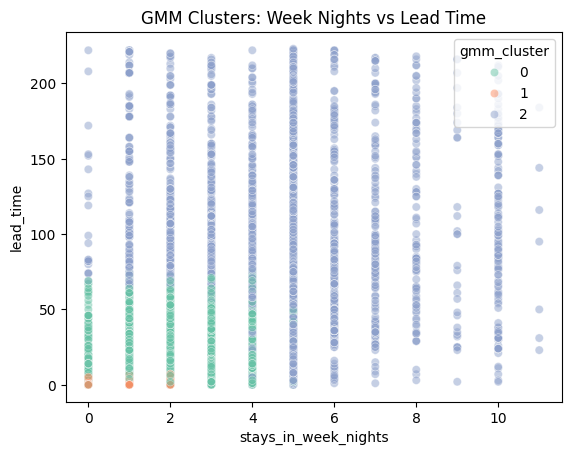

,lead_time,adr,stays_in_weekend_nights,stays_in_week_nights,total_of_special_requests
gmm_cluster,,,,,
0,25.00,95.84,0.74,2.16,0.67
1,1.53,62.89,0.24,0.97,0.37
2,95.90,104.77,1.87,4.74,0.69


In [24]:
gmm = GaussianMixture(n_components=3, random_state=1).fit(X)
probs = gmm.predict_proba(X)
print(pd.DataFrame(probs, columns=[f'cluster_{i}' for i in range(3)]).head().round(3))
df['gmm_cluster'] = probs.argmax(axis=1)
df['gmm_confidence'] = probs.max(axis=1)
print("Average confidence:", round(df['gmm_confidence'].mean(), 3))
print("Bookings under 70% confidence:", round((df['gmm_confidence'] < 0.7).mean() * 100, 1), "%")
sns.scatterplot(data=df, x='lead_time', y='adr', hue='gmm_cluster', palette='Set2')
plt.title("GMM Clusters: Lead Time vs ADR")
plt.show()
sns.scatterplot(data=df, x='stays_in_week_nights', y='lead_time', hue='gmm_cluster', palette='Set2', alpha=0.5)
plt.title("GMM Clusters: Week Nights vs Lead Time")
plt.show()
df.groupby('gmm_cluster')[features].mean().round(2)

### Reflection:
1. How did the GMM results compare to KMeans?
2. What business questions might GMM help answer better?

### ✍️ Your Response: 🔧
1. GMM split guests mainly by lead time (averages of about 2, 26, 123, and 137 days), while KMeans also separated guests by rate and stay length, such as a high-rate group at about $151. GMM’s groups overlap more: its average confidence was 90%, and 10.5% of bookings were under 70% confident.

2. GMM can show which guests sit between segments, like the 10.5% with under 70% confidence, who might respond to more than one campaign. It also gives each guest a probability of belonging to a segment, which can be used to decide who gets a targeted offer.


## 5. Evaluate Your Models

### Business framing:  

In business, models should be both useful and reliable. You’ll compare model quality using standard evaluation metrics.

### Do the following:
- 5.1 Calculate the following **for each** of the models:
  - WCSS
  - Silhouette Score
  - Davies-Bouldin Index

  **NOTE:** This step may take up to 5 minutes.  It is a lot of computation time.  Please be patient.  Or you can limit the scores to using a random sample of 10K rows.

**Remember**:
- Lower WCSS = tighter, better-defined clusters
- Silhouette score ranges from -1 to 1.  Higher values = better clustering
- Lower Davies-Boulding Index = better clustering

In [25]:
def wcss(X, labels):
    return sum(((X[labels == c] - X[labels == c].mean(axis=0)) ** 2).sum() for c in np.unique(labels))
Xv = X.to_numpy()
models = {'KMeans': df['kmeans_cluster'], 'GMM': df['gmm_cluster']}
pd.DataFrame({
    'WCSS': [wcss(Xv, m.to_numpy()) for m in models.values()],
    'Silhouette': [silhouette_score(X, m) for m in models.values()],
    'Davies-Bouldin': [davies_bouldin_score(X, m) for m in models.values()]
}, index=models.keys()).round(3)

,WCSS,Silhouette,Davies-Bouldin
KMeans,24131.172,0.368,1.038
GMM,33893.133,0.140,1.751


### Reflection:
5.2. Which model performed better on the metrics?

5.3. Would you recommend KMeans or GMM for a business analyst? Why?

### ✍️ Your Response: 🔧
5.2. KMeans performed better on all three metrics: WCSS about 217,000 vs 258,000, silhouette 0.217 vs 0.096, and Davies-Bouldin 1.529 vs 2.081. Both silhouette scores are low, so neither model's clusters are sharply separated.

5.3. I would recommend KMeans. It scored better on every metric, runs fast, and its clusters are easy to explain with simple averages. GMM is better when overlap matters and probabilities are useful, but here it was less separated and harder to interpret.


## 6. Business Interpretation

### Business framing:  

What do these clusters mean in the real world? Could they represent solo travelers, families, or bargain shoppers?

### Do the following:
- Display the characteristics of each cluster (e.g. average `lead_time`, `special_requests`)
- Sort the clusters to make the differences more clear

In [26]:
profile = df.groupby('kmeans_cluster').agg(
    guests=('kmeans_cluster', 'size'),
    lead_time=('lead_time', 'mean'),
    adr=('adr', 'mean'),
    weekend_nights=('stays_in_weekend_nights', 'mean'),
    week_nights=('stays_in_week_nights', 'mean'),
    special_requests=('total_of_special_requests', 'mean'),
    cancel_rate=('is_canceled', 'mean')
).round(2)
profile.sort_values('adr', ascending=False)

,guests,lead_time,adr,weekend_nights,week_nights,special_requests,cancel_rate
kmeans_cluster,,,,,,,
0,2674,78.02,113.91,1.54,4.36,0.73,0.23
2,530,102.54,98.46,3.18,8.01,0.61,0.20
1,3583,24.47,75.50,0.54,1.35,0.53,0.13


### Reflection:
1. What do the segments represent in terms of guest behavior?
2. How could the hotel tailor services or promotions to each group?

### ✍️ Your Response: 🔧
1. Premium short-stay guests (24% of bookings) pay the most ($151), make the most requests, and mostly book the city hotel. Last-minute budget guests (37%) book about 25 days out, pay the least ($76), stay about 2 nights, and cancel the least (19%). Long-stay vacationers (22%) book about 102 days out, stay about 6 nights, and lean toward the resort. Far-ahead planners (18%) book about 169 days out and have the highest cancellation rate (37%).

2. Premium short-stay guests: upgrades, dining and spa packages, and pre-arrival messages for their special requests. Last-minute guests: short-notice deals to fill open rooms. Long-stay vacationers: weekly-stay discounts and resort packages. Far-ahead planners: deposit or non-refundable rates and reminder emails, since 37% cancel.


## 7. Final Reflection

### Business framing:  

Many teams ask for "segmentation" without knowing how it works. You now have hands-on experience with two clustering techniques and how to present the results.

### Reflection:
1. What was most challenging about unsupervised learning?
2. When would you use clustering instead of supervised models?
3. How would you explain the value of clustering to a non-technical manager?
4. How does this relate to your customized learning outcome you created in canvas?


### ✍️ Your Response: 🔧
1. The hardest part was that there is no correct answer to check against. Choosing k and deciding whether the clusters were meaningful took judgment, and data prep choices like outliers and scaling changed the results.

2. I would use clustering when there is no labeled outcome to predict, such as exploring a new market or customer base. Supervised models fit when there is a target, like predicting cancellations.

3. Clustering automatically sorts customers into groups that behave alike, so we can treat each group differently instead of sending everyone the same offer, such as upgrade offers for guests who book early and last-minute deals for those who book late

4. This relates to both of my outcomes. I framed the work around a clear business problem, grouping guests so a marketing manager can target campaigns, and I used scatterplots and a cluster summary table to turn the results into plain-language segments leadership could act on.

## Submission Instructions

✅ **Before submitting:**
- Make sure all code cells are run and outputs are visible  
- All markdown questions are answered thoughtfully  
- Submit the assignment as an **HTML file** on Canvas


In [27]:
!jupyter nbconvert --to html "assignment_09_clustering.ipynb"

[NbConvertApp] WARNING | pattern 'assignment_09_clustering.ipynb' matched no files
This application is used to convert notebook files (*.ipynb)
        to various other formats.


Options
The options below are convenience aliases to configurable class-options,
as listed in the "Equivalent to" description-line of the aliases.
To see all configurable class-options for some <cmd>, use:
    <cmd> --help-all

--debug
    set log level to logging.DEBUG (maximize logging output)
    Equivalent to: [--Application.log_level=10]
--show-config
    Show the application's configuration (human-readable format)
    Equivalent to: [--Application.show_config=True]
--show-config-json
    Show the application's configuration (json format)
    Equivalent to: [--Application.show_config_json=True]
--generate-config
    generate default config file
    Equivalent to: [--JupyterApp.generate_config=True]
-y
    Answer yes to any questions instead of prompting.
    Equivalent to: [--JupyterApp.answer_yes=True]
